In [ ]:
import pandas as pd

df = pd.read_csv('Marcello FINAL CIS450 MEDICAID.csv')
df

,NDC CODE,State,Region,Quarter,Product Name,Units Reimbursed,Medicaid Amount Reimbursed,Cost per Unit,PROPRIETARYNAME,NONPROPRIETARYNAME,BRAND OR GENERIC,LABELERNAME,PHARM_CLASSES,Drug Class
0,20213,AL,South,4,HUMULIN R,55.60,144.56,2.60,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
1,20213,AL,South,3,HUMULIN R,39.75,103.35,2.60,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
2,20213,AL,South,2,HUMULIN R,102.30,625.23,6.11,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
3,20213,AL,South,1,HUMULIN R,165.65,1091.01,6.59,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
4,20213,CA,West,4,HUMULIN R,394.80,2168.57,5.49,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
504625,839800003,CT,Northeast,4,FUROSEMIDE,512.00,150.06,0.29,Furosemide,Furosemide,Generic,Ipca Laboratories Limited,"Increased Diuresis at Loop of Henle [PE], Loop...",Cardiovascular
504626,839800003,FL,South,4,FUROSEMIDE,3569.00,472.84,0.13,Furosemide,Furosemide,Generic,Ipca Laboratories Limited,"Increased Diuresis at Loop of Henle [PE], Loop...",Cardiovascular
504627,839800004,CA,West,4,FUROSEMIDE,1680.00,221.36,0.13,Furosemide,Furosemide,Generic,Ipca Laboratories Limited,"Increased Diuresis at Loop of Henle [PE], Loop...",Cardiovascular
504628,839800005,CA,West,4,PROPRANOLO,989.00,332.19,0.34,Propranolol Hydrochloride,Propranolol Hydrochloride,Generic,Ipca Laboratories Limited,"Adrenergic beta-Antagonists [MoA], beta-Adrene...",Cardiovascular


In [ ]:
# ===========================================
# Q4–Q5 DATA CLEANING (EXACT SAME AS Q3 + REMOVE 'Other')
# ===========================================

import pandas as pd
import numpy as np
import re

# 1. Drop rows missing key descriptive fields
df_clean = df.dropna(subset=[
    'NONPROPRIETARYNAME',
    'BRAND OR GENERIC',
    'PHARM_CLASSES',
    'Drug Class'
]).copy()

# 2. Normalize strings
string_cols = ['NONPROPRIETARYNAME','BRAND OR GENERIC','PHARM_CLASSES',
               'Drug Class','State','Region','LABELERNAME','Product Name']

for col in string_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 🔥 3. REMOVE “Other” drug class (recommended for Q4–Q5 analysis)
df_clean = df_clean[df_clean['Drug Class'].str.lower() != 'other'].copy()

# 4. Brand/generic flag
df_clean['is_brand'] = df_clean['BRAND OR GENERIC'].str.lower().eq('brand').astype(int)

# 5. Cleaned ingredient name (same as Q3)
def clean_ing(s):
    s = str(s).lower()
    tokens = [
        'hydrochloride','hcl','sodium','phosphate','mg','tablet','capsule',
        'injection','solution','extended release','extended-release','er','sr',
        'film-coated','enteric-coated','oral','suspension'
    ]
    for t in tokens:
        s = s.replace(t, ' ')
    s = re.sub(r'[^a-z0-9\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

df_clean['cleaned_name'] = df_clean['NONPROPRIETARYNAME'].apply(clean_ing)

# 6. Log transforms (for Q4 modeling)
df_clean['log_cost_unit'] = np.log1p(df_clean['Cost per Unit'])
df_clean['log_amount']    = np.log1p(df_clean['Medicaid Amount Reimbursed'])
df_clean['log_units']     = np.log1p(df_clean['Units Reimbursed'])

# 7. Check
print("Rows after cleaning and removing 'Other':", df_clean.shape[0])
print(df_clean['Drug Class'].value_counts())
print("\nRemaining nulls:")
print(df_clean.isnull().sum())

Rows after cleaning and removing 'Other': 195003
Drug Class
Cardiovascular             45566
Mental Health              39147
Hormonal / Endocrine       31407
Anti-infective             26847
GI / Acid Suppression      18240
Pain / Analgesic           14947
Immunology / Autoimmune     9358
Antidiabetic                5878
Respiratory                 2742
Oncology                     871
Name: count, dtype: int64

Remaining nulls:
NDC CODE                      0
State                         0
Region                        0
Quarter                       0
Product Name                  0
Units Reimbursed              0
Medicaid Amount Reimbursed    0
Cost per Unit                 0
PROPRIETARYNAME               0
NONPROPRIETARYNAME            0
BRAND OR GENERIC              0
LABELERNAME                   0
PHARM_CLASSES                 0
Drug Class                    0
is_brand                      0
cleaned_name                  0
log_cost_unit                 0
log_amount            

#Q4

In [ ]:
# Q4 — Use df_clean
print("Brand vs Generic Cost per Unit:")
print(df_clean.groupby('BRAND OR GENERIC')['Cost per Unit'].agg(['mean','median','count']))

print("\nMedian Cost per Unit by Drug Class:")
print(df_clean.groupby('Drug Class')['Cost per Unit'].median().sort_values(ascending=False))

Brand vs Generic Cost per Unit:
                        mean  median   count
BRAND OR GENERIC                            
Brand             448.363577    9.97   37881
Generic             3.924931    0.39  157122

Median Cost per Unit by Drug Class:
Drug Class
Oncology                   124.820
Antidiabetic                15.745
Immunology / Autoimmune      9.355
Hormonal / Endocrine         0.750
Anti-infective               0.610
Pain / Analgesic             0.480
Mental Health                0.410
GI / Acid Suppression        0.340
Cardiovascular               0.310
Respiratory                  0.290
Name: Cost per Unit, dtype: float64



Feature Importance — Drivers of Cost:
is_brand         0.423281
PHARM_CLASSES    0.225909
log_units        0.193852
Drug Class       0.124967
State            0.025742
Region           0.006250
dtype: float64


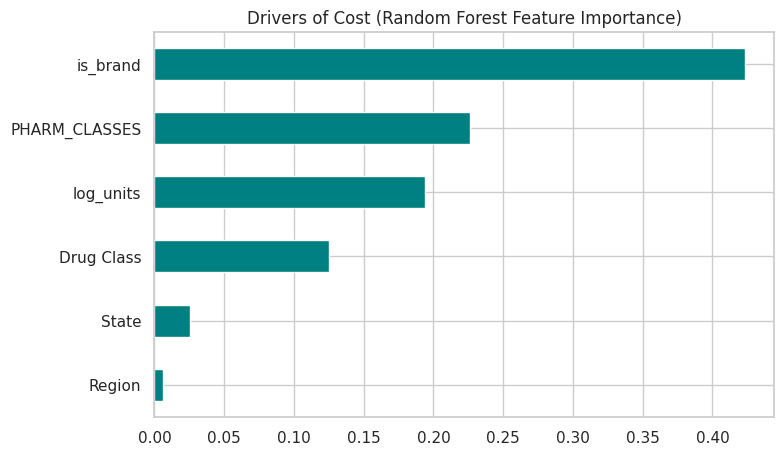

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')

# Encode categorical features
work = df_clean.copy()

for col in ['Drug Class','PHARM_CLASSES','State','Region']:
    le = LabelEncoder()
    work[col] = le.fit_transform(work[col].astype(str))

# Build feature matrix
X = work[['is_brand','log_units','Drug Class','PHARM_CLASSES','State','Region']]
y = work['log_cost_unit']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature Importance — Drivers of Cost:")
print(importances)

plt.figure(figsize=(8,5))
importances.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title("Drivers of Cost (Random Forest Feature Importance)")
plt.show()

In [ ]:
median_cost = df_clean.groupby('NONPROPRIETARYNAME')['Cost per Unit'].median()
print("Top 15 Ingredients by Median Cost per Unit:")
print(median_cost.sort_values(ascending=False).head(15))

Top 15 Ingredients by Median Cost per Unit:
NONPROPRIETARYNAME
histrelin acetate           43452.400
ustekinumab                 25528.270
Leuprolide Acetate          25257.655
pegloticase                 23385.700
risankizumab-rzaa           19241.630
teprotumumab                16147.145
Guselkumab                  13098.450
tildrakizumab-asmn          10513.020
LANREOTIDE ACETATE          10362.500
lanreotide acetate           8512.820
brentuximab vedotin          8364.710
Repository Corticotropin     8346.455
ixekizumab                   6649.560
Benralizumab                 5283.970
mirikizumab-mrkz             5185.640
Name: Cost per Unit, dtype: float64


In [ ]:
total_spend = df_clean.groupby('NONPROPRIETARYNAME')['Medicaid Amount Reimbursed'].sum()
print("Top 15 Drugs by Total Medicaid Spending:")
print(total_spend.sort_values(ascending=False).head(15))

Top 15 Drugs by Total Medicaid Spending:
NONPROPRIETARYNAME
semaglutide                                                              1.943185e+09
bictegravir sodium, emtricitabine, and tenofovir alafenamide fumarate    9.119567e+08
paliperidone palmitate                                                   7.143266e+08
Empagliflozin                                                            6.696734e+08
Dupilumab                                                                6.195012e+08
Dulaglutide                                                              4.208797e+08
ustekinumab                                                              3.701307e+08
tirzepatide                                                              3.338462e+08
risankizumab-rzaa                                                        3.333628e+08
secukinumab                                                              3.267439e+08
DAPAGLIFLOZIN                                                            2.67005

#Q5

In [ ]:
region_summary = df_clean.groupby('Region').agg(
    total_spend  = ('Medicaid Amount Reimbursed', 'sum'),
    median_cpu   = ('Cost per Unit', 'median'),
    mean_cpu     = ('Cost per Unit', 'mean'),
    total_units  = ('Units Reimbursed', 'sum'),
    n_records    = ('Cost per Unit', 'count')
).sort_values('total_spend', ascending=False)

print("Region Summary:")
print(region_summary)

Region Summary:
            total_spend  median_cpu    mean_cpu   total_units  n_records
Region                                                                  
West       9.878486e+09        0.55   96.149178  2.224053e+09      83174
South      2.866363e+09        0.41   81.860835  1.152006e+09      96854
Northeast  1.041569e+09        0.50  111.885993  1.959637e+08      14975


In [ ]:
state_summary = df_clean.groupby('State').agg(
    total_spend=('Medicaid Amount Reimbursed','sum'),
    median_cpu=('Cost per Unit','median'),
    mean_cpu=('Cost per Unit','mean'),
    total_units=('Units Reimbursed','sum')
).sort_values('total_spend', ascending=False)

print("Top 10 States by Spending:")
print(state_summary.head(10))

Top 10 States by Spending:
        total_spend  median_cpu    mean_cpu   total_units
State                                                    
CA     8.147932e+09        0.75   97.923217  1.754010e+09
FL     1.320431e+09        0.43  103.553412  5.396609e+08
CT     1.041569e+09        0.50  111.885993  1.959637e+08
AZ     8.689405e+08        0.45   93.367661  2.405506e+08
CO     6.358621e+08        0.45   97.149672  1.688783e+08
GA     5.659411e+08        0.40   72.937263  2.893490e+08
AL     4.675588e+08        0.47   96.857852  1.698557e+08
AR     1.987989e+08        0.43   68.666109  9.071405e+07
DC     1.833546e+08        0.30   61.215619  2.434505e+07
DE     1.302777e+08        0.32   65.506517  3.808126e+07


In [ ]:
from scipy.stats import kruskal

groups = [g['Cost per Unit'].values for _, g in df_clean.groupby('Region')]
stat, p = kruskal(*groups)

print(f"Kruskal-Wallis Test: stat={stat:.2f}, p={p:.3g}")

if p < 0.05:
    print("=> Significant Differences in Cost per Unit Across Regions")
else:
    print("=> No Significant Regional Differences Detected")

Kruskal-Wallis Test: stat=2606.20, p=0
=> Significant Differences in Cost per Unit Across Regions


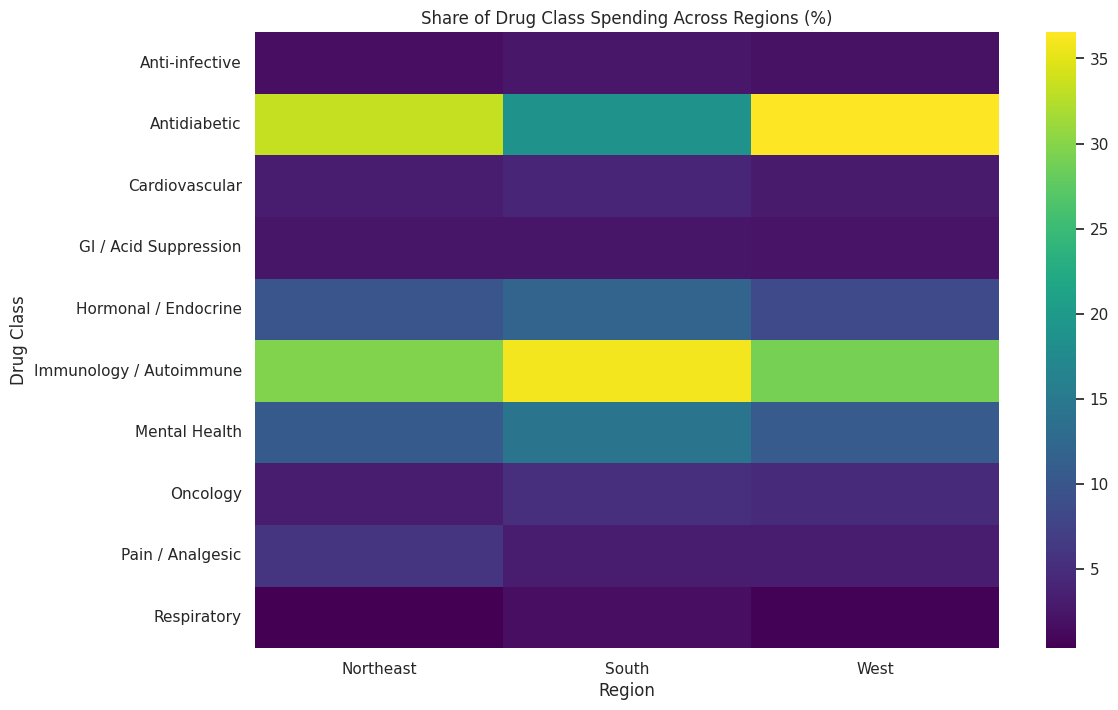

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

class_region = df_clean.pivot_table(
    index='Drug Class',
    columns='Region',
    values='Medicaid Amount Reimbursed',
    aggfunc='sum',
    fill_value=0
)

class_region_pct = class_region.div(class_region.sum(), axis=1) * 100

plt.figure(figsize=(12,8))
sns.heatmap(class_region_pct, cmap='viridis')
plt.title("Share of Drug Class Spending Across Regions (%)")
plt.show()

In [ ]:
def top_drugs_by_region(region, n=5):
    sub = df_clean[df_clean['Region'] == region]
    return (
        sub.groupby('NONPROPRIETARYNAME')['Medicaid Amount Reimbursed']
           .sum()
           .sort_values(ascending=False)
           .head(n)
    )

for r in df_clean['Region'].unique():
    print(f"\nTop drugs in region: {r}")
    print(top_drugs_by_region(r))


Top drugs in region: South
NONPROPRIETARYNAME
bictegravir sodium, emtricitabine, and tenofovir alafenamide fumarate    2.603101e+08
Dupilumab                                                                2.243644e+08
paliperidone palmitate                                                   1.750089e+08
semaglutide                                                              1.461456e+08
ustekinumab                                                              1.100090e+08
Name: Medicaid Amount Reimbursed, dtype: float64

Top drugs in region: West
NONPROPRIETARYNAME
semaglutide                                                              1.628907e+09
bictegravir sodium, emtricitabine, and tenofovir alafenamide fumarate    6.029707e+08
Empagliflozin                                                            5.360773e+08
paliperidone palmitate                                                   5.194879e+08
Dupilumab                                                                3.398053e+0

#Q4
Medicaid’s drug costs are driven primarily by the distinction between brand and generic medications, with brand drugs showing a median cost per unit nearly 25 times higher than generics. Among therapeutic categories, Oncology, Antidiabetic, and Immunology/Autoimmune drugs stand out as the most expensive, reflecting their role as specialty or chronic-disease treatments with high variability and extreme outliers. Random Forest analysis confirms that brand status, drug class, and ingredient identity are the strongest predictors of cost, while state and region have comparatively minor influence. Overall, Medicaid spending is concentrated in high-cost specialty drugs and chronic disease treatments, making these areas the primary drivers of rising pharmaceutical costs.

#Q5
Regions vary significantly in Medicaid drug spending and pricing, with the West accounting for the highest total expenditures and showing greater cost variability. A Kruskal-Wallis statistical test confirms that cost-per-unit differs significantly across regions, indicating that geographic factors influence pricing. Despite these differences, all regions spend heavily on the same key high-cost drugs—such as semaglutide, HIV antivirals, and autoimmune biologics—suggesting that the variation is driven more by differences in utilization volume than differences in drug mix. The regional heatmap reinforces this pattern, showing consistent reliance on chronic-disease drug classes across the country.